# Yemen Maize Production Prediction (1961–2024)

## 1. Project Overview

### Background
This project analyzes historical maize production in Yemen from 1961 to 2024 using agricultural statistics and available rainfall data.

### Research Objective
The main objective is to analyze historical production patterns, evaluate forecasting methods using time-ordered validation, and generate cautious forecasts for 2025–2027.

### Problem Type
Time-series regression and agricultural production forecasting.

### Target Variable
`Production` — annual maize production in tonnes.

### Data Sources
- FAOSTAT agricultural production statistics.
- Annual rainfall data for 1981–2024.

### Methodological Principles
- Inspect and validate data before modeling.
- Distinguish official, external, estimated, and imputed observations.
- Prevent data leakage during feature engineering and evaluation.
- Compare forecasting models against simple baselines.
- Report limitations and uncertainty transparently.

In [8]:
# 2. Import Libraries and Configure Project Paths

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project directory in Google Drive
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Yemen_Maize_Prediction"
)

# Data and results directories
DATA_DIR = PROJECT_DIR / "01_Data"
RESULTS_DIR = PROJECT_DIR / "05_Results"
FIGURES_DIR = RESULTS_DIR / "figures"

# Create output directories if they do not exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120

print("Project directory exists:", PROJECT_DIR.exists())
print("Data directory exists:", DATA_DIR.exists())
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

Project directory exists: True
Data directory exists: False
Results directory: /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results
Figures directory: /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/figures


In [9]:
# 3. Locate Existing Project Files in Google Drive

from pathlib import Path

DRIVE_DIR = Path("/content/drive/MyDrive")

keywords = [
    "Stage2_Temporal_Features.csv",
    "Yemen_Maize_Annual_Full_1961_2024.csv",
    "Yemen_Maize_Rainfall_1981_2024.csv",
    "yemen_annual_rainfall_1981_2024.csv",
    "Stage40_Method_Summary.csv",
    "Stage27_Recursive_Forecasts_2025_2027.csv",
]

for keyword in keywords:
    matches = list(DRIVE_DIR.rglob(keyword))

    print(f"\n{keyword}")

    if matches:
        for path in matches:
            print("  FOUND:", path)
    else:
        print("  Not found")


Stage2_Temporal_Features.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/Stage2_Temporal_Features.csv

Yemen_Maize_Annual_Full_1961_2024.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/Yemen_Maize_Annual_Full_1961_2024.csv

Yemen_Maize_Rainfall_1981_2024.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/Yemen_Maize_Rainfall_1981_2024.csv

yemen_annual_rainfall_1981_2024.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/yemen_annual_rainfall_1981_2024.csv

Stage40_Method_Summary.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/Stage40_Method_Summary.csv

Stage27_Recursive_Forecasts_2025_2027.csv
  FOUND: /content/drive/MyDrive/Yemen_Maize_Prediction/Stage27_Recursive_Forecasts_2025_2027.csv


In [10]:
# 4. Load and Inspect Existing Project Data

# Define paths to existing files
TEMPORAL_FILE = PROJECT_DIR / "Stage2_Temporal_Features.csv"
ANNUAL_FILE = PROJECT_DIR / "Yemen_Maize_Annual_Full_1961_2024.csv"
RAINFALL_FILE = PROJECT_DIR / "Yemen_Maize_Rainfall_1981_2024.csv"
METHODS_FILE = PROJECT_DIR / "Stage40_Method_Summary.csv"
FORECAST_FILE = PROJECT_DIR / "Stage27_Recursive_Forecasts_2025_2027.csv"

# Load available datasets
temporal_df = pd.read_csv(TEMPORAL_FILE)
annual_df = pd.read_csv(ANNUAL_FILE)
rainfall_df = pd.read_csv(RAINFALL_FILE)

print("=" * 70)
print("TEMPORAL FEATURES DATASET")
print("=" * 70)
print("Shape:", temporal_df.shape)
print("\nColumns:")
print(temporal_df.columns.tolist())
print("\nFirst 5 rows:")
display(temporal_df.head())

print("\nData types:")
print(temporal_df.dtypes)

print("\nMissing values:")
display(temporal_df.isna().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", temporal_df.duplicated().sum())


print("\n" + "=" * 70)
print("ANNUAL DATASET")
print("=" * 70)
print("Shape:", annual_df.shape)
print("Columns:", annual_df.columns.tolist())
display(annual_df.head())


print("\n" + "=" * 70)
print("RAINFALL DATASET")
print("=" * 70)
print("Shape:", rainfall_df.shape)
print("Columns:", rainfall_df.columns.tolist())
display(rainfall_df.head())


print("\n" + "=" * 70)
print("SAVED MODEL RESULTS")
print("=" * 70)

if METHODS_FILE.exists():
    methods_df = pd.read_csv(METHODS_FILE)
    print("Method summary shape:", methods_df.shape)
    display(methods_df.head())
else:
    print("Method summary file not found.")

if FORECAST_FILE.exists():
    forecasts_df = pd.read_csv(FORECAST_FILE)
    print("Forecast results shape:", forecasts_df.shape)
    display(forecasts_df.head())
else:
    print("Forecast file not found.")

TEMPORAL FEATURES DATASET
Shape: (64, 21)

Columns:
['Year', 'Area_Harvested', 'Production', 'Yield', 'Production_Unit', 'Production_Flag', 'Production_Note', 'Area_Unit', 'Area_Flag', 'Area_Note', 'Yield_Unit', 'Yield_Flag', 'Yield_Note', 'Rainfall_mm', 'Image_Count', 'Previous_Year', 'Production_Lag_1', 'Production_Lag_2', 'Production_Lag_3', 'Production_Rolling_Mean_3', 'Rainfall_Lag_1']

First 5 rows:


,Year,Area_Harvested,Production,Yield,Production_Unit,Production_Flag,Production_Note,Area_Unit,Area_Flag,Area_Note,Yield_Unit,Yield_Flag,Yield_Note,Rainfall_mm,Image_Count,Previous_Year,Production_Lag_1,Production_Lag_2,Production_Lag_3,Production_Rolling_Mean_3,Rainfall_Lag_1
0,1961,5000.0,12200.0,2440.0,t,E,NaN,ha,E,NaN,kg/ha,E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1962,5200.0,12700.0,2442.3,t,E,NaN,ha,E,NaN,kg/ha,E,NaN,NaN,NaN,1961.0,12200.0,NaN,NaN,NaN,NaN
2,1963,5300.0,13000.0,2452.8,t,E,NaN,ha,E,NaN,kg/ha,E,NaN,NaN,NaN,1962.0,12700.0,12200.0,NaN,NaN,NaN
3,1964,5400.0,13200.0,2444.4,t,E,NaN,ha,E,NaN,kg/ha,E,NaN,NaN,NaN,1963.0,13000.0,12700.0,12200.0,12633.333333,NaN
4,1965,5500.0,13500.0,2454.5,t,X,Unofficial figure,ha,X,Unofficial figure,kg/ha,X,NaN,NaN,NaN,1964.0,13200.0,13000.0,12700.0,12966.666667,NaN



Data types:
Year                           int64
Area_Harvested               float64
Production                   float64
Yield                        float64
Production_Unit               object
Production_Flag               object
Production_Note               object
Area_Unit                     object
Area_Flag                     object
Area_Note                     object
Yield_Unit                    object
Yield_Flag                    object
Yield_Note                   float64
Rainfall_mm                  float64
Image_Count                  float64
Previous_Year                float64
Production_Lag_1             float64
Production_Lag_2             float64
Production_Lag_3             float64
Production_Rolling_Mean_3    float64
Rainfall_Lag_1               float64
dtype: object

Missing values:


,Missing Values
Year,0
Area_Harvested,0
Production,0
Yield,0
Production_Unit,0
Production_Flag,0
Production_Note,44
Area_Unit,0
Area_Flag,0
Area_Note,46



Duplicate rows: 0

ANNUAL DATASET
Shape: (64, 15)
Columns: ['Year', 'Area_Harvested', 'Production', 'Yield', 'Production_Unit', 'Production_Flag', 'Production_Note', 'Area_Unit', 'Area_Flag', 'Area_Note', 'Yield_Unit', 'Yield_Flag', 'Yield_Note', 'Rainfall_mm', 'Image_Count']


...

,Year,Area_Harvested,Production,Yield,Production_Unit,Production_Flag,Production_Note,Area_Unit,Area_Flag,Area_Note,Yield_Unit,Yield_Flag,Yield_Note,Rainfall_mm,Image_Count
0,1981,40481.0,68705.0,1697.2,t,X,Unofficial figure,ha,X,Unofficial figure,kg/ha,X,NaN,147.726018,72
1,1982,42802.0,74205.0,1733.7,t,X,Unofficial figure,ha,X,Unofficial figure,kg/ha,X,NaN,159.250523,72
2,1983,41602.0,40463.0,972.6,t,X,Unofficial figure,ha,X,Unofficial figure,kg/ha,X,NaN,270.523556,72
3,1984,40284.0,49502.0,1228.8,t,X,Unofficial figure,ha,X,Unofficial figure,kg/ha,X,NaN,90.152165,72
4,1985,42000.0,46000.0,1095.2,t,A,NaN,ha,A,NaN,kg/ha,A,NaN,117.907748,72



SAVED MODEL RESULTS
Method summary shape: (5, 4)


,Method,Horizons_Evaluated,Mean_MAE_Across_Horizons,Mean_RMSE_Across_Horizons
0,Ridge_Area_Yield,3,14935.424096,18842.502410
1,Ridge_Direct,3,15086.920430,18777.675645
2,Previous_Year,3,15861.051864,20637.840702
3,Three_Year_Average,3,16436.588039,20932.072562
4,Ridge_Log_Change,3,18034.828268,23265.495966


Forecast results shape: (12, 5)


,Model,Year,Prediction,Training_Records,Training_End_Year
0,Previous_Year,2025,58000.000000,NaN,NaN
1,Ridge_A_and_X_alpha_10,2025,59306.228107,60.0,2024.0
2,Ridge_A_only_alpha_10,2025,59974.434998,40.0,2019.0
3,Three_Year_Average,2025,71541.000000,NaN,NaN
4,Previous_Year,2026,58000.000000,NaN,NaN


## 5. Data Quality Audit

This section evaluates data completeness, year continuity, source-quality flags, and the correctness of time-dependent features before exploratory analysis or model evaluation.

Missing values are assessed in context rather than removed automatically. Historical lag features are checked against the original production series to identify possible calculation errors or temporal leakage.

In [11]:
# 5. Data Quality Audit

# 1. Check year range and continuity
years = sorted(annual_df["Year"].dropna().astype(int).unique())
expected_years = list(range(min(years), max(years) + 1))

print("YEAR COVERAGE")
print("First year:", min(years))
print("Last year:", max(years))
print("Number of unique years:", len(years))
print("Missing years:", sorted(set(expected_years) - set(years)))
print("Duplicate years:", annual_df["Year"].duplicated().sum())


# 2. Check invalid or missing values in key numeric columns
numeric_columns = [
    "Area_Harvested",
    "Production",
    "Yield",
    "Rainfall_mm"
]

quality_summary = pd.DataFrame({
    "Missing_Count": annual_df[numeric_columns].isna().sum(),
    "Zero_Count": (annual_df[numeric_columns] == 0).sum(),
    "Negative_Count": (annual_df[numeric_columns] < 0).sum()
})

print("\nNUMERIC DATA QUALITY")
display(quality_summary)


# 3. Summarize source flags
flag_summary = pd.concat(
    {
        "Production": annual_df["Production_Flag"].value_counts(dropna=False),
        "Area": annual_df["Area_Flag"].value_counts(dropna=False),
        "Yield": annual_df["Yield_Flag"].value_counts(dropna=False)
    },
    axis=1
).fillna(0).astype(int)

print("\nSOURCE FLAG COUNTS")
display(flag_summary)


# 4. Verify lag features against historical production
# Shift values by row order, then compare only where years are consecutive.
check_df = temporal_df.sort_values("Year").copy()

for lag in [1, 2, 3]:
    expected_lag = check_df["Production"].shift(lag)
    consecutive = check_df["Year"].diff(lag).eq(lag)

    valid = (
        consecutive
        & expected_lag.notna()
        & check_df[f"Production_Lag_{lag}"].notna()
    )

    mismatch = (
        check_df.loc[valid, f"Production_Lag_{lag}"]
        - expected_lag.loc[valid]
    ).abs() > 1e-6

    print(
        f"Production_Lag_{lag}:",
        int(mismatch.sum()),
        "mismatches across",
        int(valid.sum()),
        "comparable rows"
    )


# 5. Inspect recent observations and their quality notes
recent_columns = [
    "Year",
    "Production",
    "Production_Flag",
    "Production_Note",
    "Area_Harvested",
    "Area_Flag",
    "Yield",
    "Yield_Flag",
    "Rainfall_mm"
]

print("\nRECENT OBSERVATIONS (2019–2024)")
display(
    annual_df.loc[
        annual_df["Year"].between(2019, 2024),
        recent_columns
    ].sort_values("Year")
)

YEAR COVERAGE
First year: 1961
Last year: 2024
Number of unique years: 64
Missing years: []
Duplicate years: 0

NUMERIC DATA QUALITY


,Missing_Count,Zero_Count,Negative_Count
Area_Harvested,0,0,0
Production,0,0,0
Yield,0,0,0
Rainfall_mm,20,0,0



SOURCE FLAG COUNTS


,Production,Area,Yield
A,40,40,40
X,20,18,18
E,4,4,6
I,0,2,0


Production_Lag_1: 0 mismatches across 63 comparable rows
Production_Lag_2: 0 mismatches across 62 comparable rows
Production_Lag_3: 0 mismatches across 61 comparable rows

RECENT OBSERVATIONS (2019–2024)


,Year,Production,Production_Flag,Production_Note,Area_Harvested,Area_Flag,Yield,Yield_Flag,Rainfall_mm
58,2019,48290.0,A,NaN,36578.0,A,1320.2,A,142.541055
59,2020,86159.0,X,Unofficial figure,37794.0,X,2279.7,X,277.438126
60,2021,94375.0,X,Unofficial figure,38437.0,X,2455.3,X,177.333176
61,2022,96623.0,X,Unofficial figure,39145.0,X,2468.3,X,214.766540
62,2023,60000.0,X,Unofficial figure,24587.0,I,2440.3,E,197.231706
63,2024,58000.0,X,Unofficial figure,37006.0,I,1567.3,E,190.645596


## 6. Exploratory Data Analysis (EDA)

This section explores long-term maize production patterns, harvested area, yield, rainfall availability, and the distribution of production-quality flags.

The visualizations help identify trends, variability, and unusual changes before modeling. They describe historical associations and do not establish causal relationships.

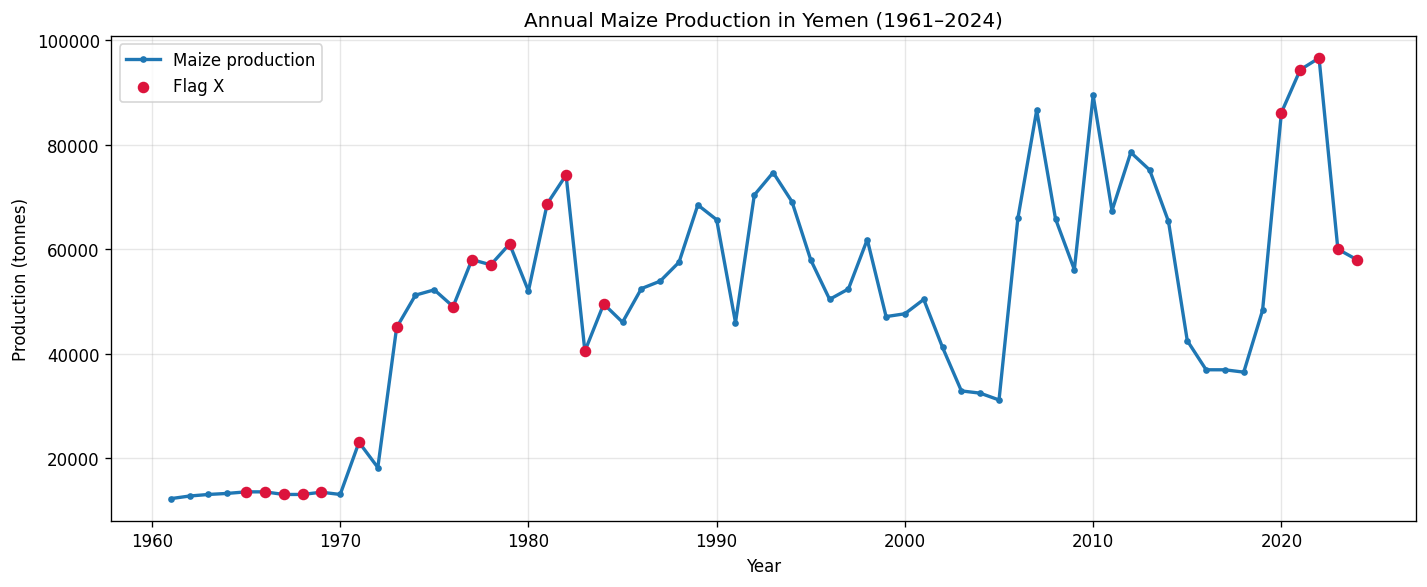

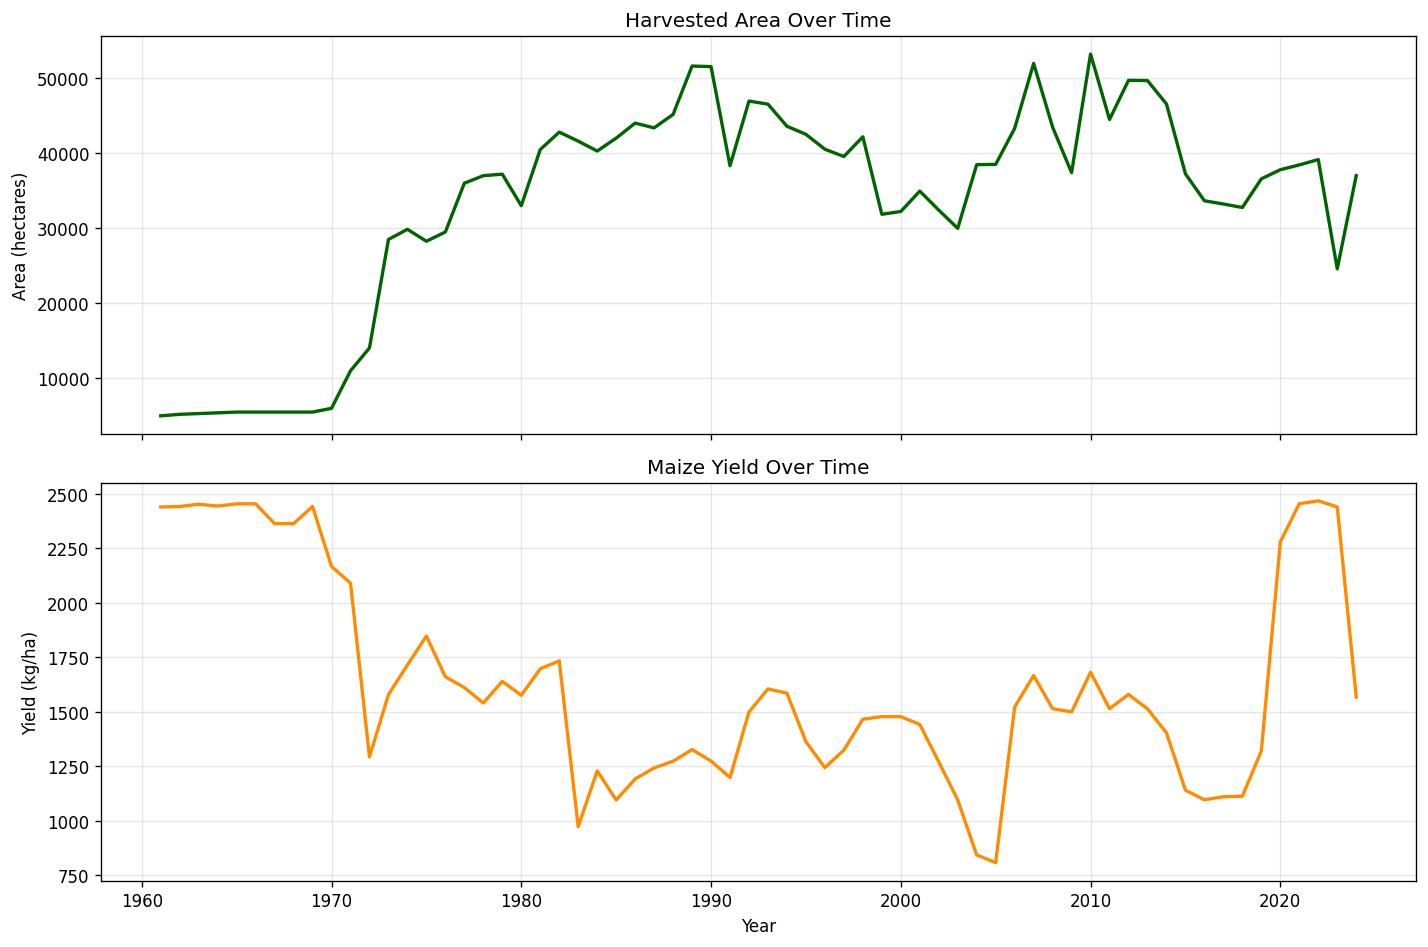

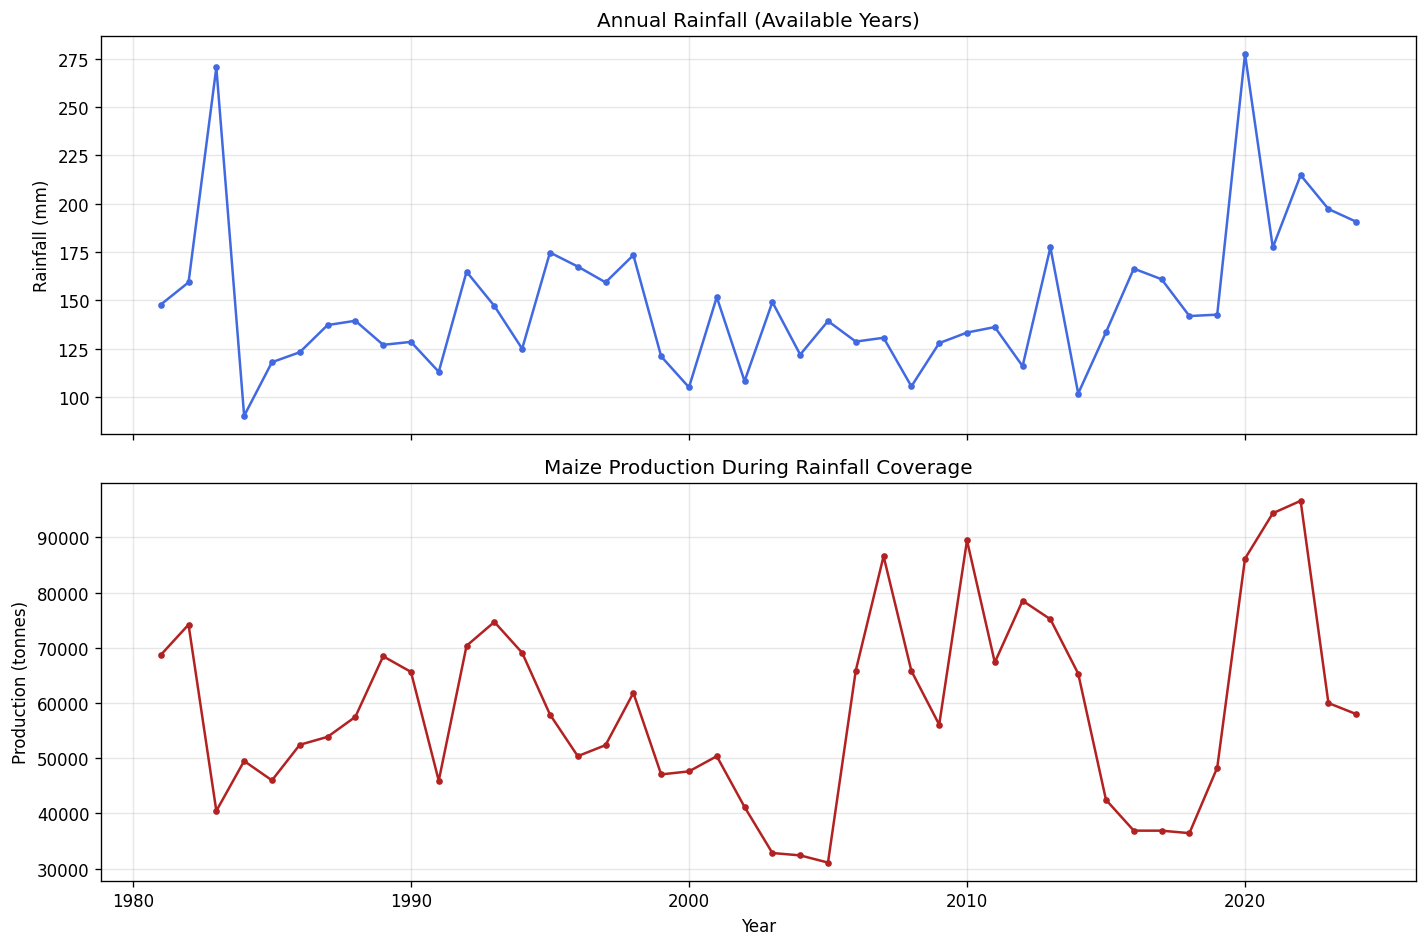

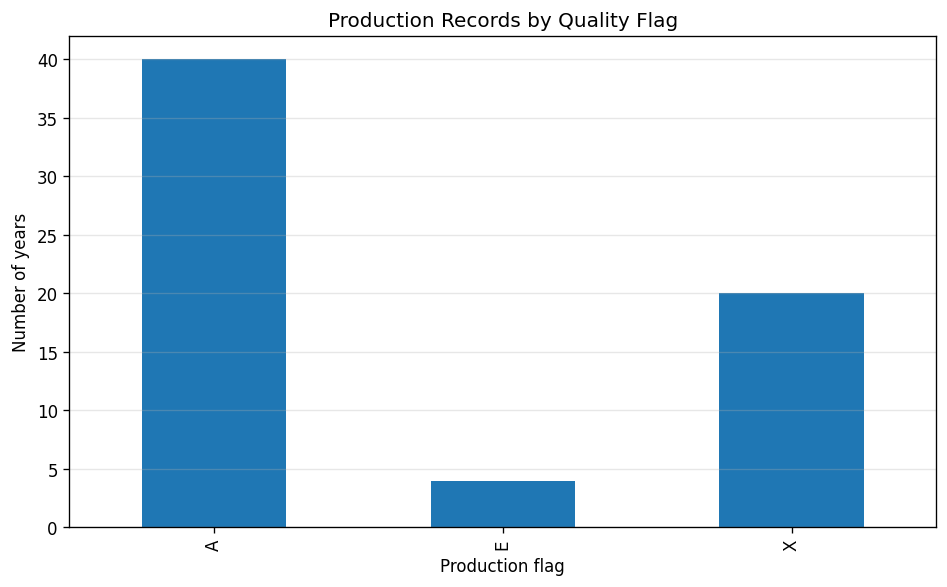

EDA figures saved to: /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/figures


In [12]:
# 6. Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt

eda_df = annual_df.sort_values("Year").copy()

# Ensure the output directory exists
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# Figure 1: Historical maize production
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    eda_df["Year"],
    eda_df["Production"],
    linewidth=2,
    marker="o",
    markersize=3,
    label="Maize production"
)

# Highlight observations with external-organization flags
external = eda_df["Production_Flag"].eq("X")

ax.scatter(
    eda_df.loc[external, "Year"],
    eda_df.loc[external, "Production"],
    color="crimson",
    s=35,
    label="Flag X",
    zorder=3
)

ax.set_title("Annual Maize Production in Yemen (1961–2024)")
ax.set_xlabel("Year")
ax.set_ylabel("Production (tonnes)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "01_maize_production_history.png",
    bbox_inches="tight"
)
plt.show()


# Figure 2: Harvested area and yield
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    eda_df["Year"],
    eda_df["Area_Harvested"],
    color="darkgreen",
    linewidth=2
)
axes[0].set_title("Harvested Area Over Time")
axes[0].set_ylabel("Area (hectares)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    eda_df["Year"],
    eda_df["Yield"],
    color="darkorange",
    linewidth=2
)
axes[1].set_title("Maize Yield Over Time")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Yield (kg/ha)")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "02_area_and_yield.png",
    bbox_inches="tight"
)
plt.show()


# Figure 3: Rainfall and production during overlapping years
rain_df = eda_df.dropna(subset=["Rainfall_mm"]).copy()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    rain_df["Year"],
    rain_df["Rainfall_mm"],
    color="royalblue",
    marker="o",
    markersize=3
)
axes[0].set_title("Annual Rainfall (Available Years)")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    rain_df["Year"],
    rain_df["Production"],
    color="firebrick",
    marker="o",
    markersize=3
)
axes[1].set_title("Maize Production During Rainfall Coverage")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Production (tonnes)")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "03_rainfall_and_production.png",
    bbox_inches="tight"
)
plt.show()


# Figure 4: Production flag counts
flag_counts = (
    eda_df["Production_Flag"]
    .fillna("Missing")
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

flag_counts.plot(kind="bar", ax=ax)

ax.set_title("Production Records by Quality Flag")
ax.set_xlabel("Production flag")
ax.set_ylabel("Number of years")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "04_production_flag_counts.png",
    bbox_inches="tight"
)
plt.show()


print("EDA figures saved to:", FIGURES_DIR)

## 7. Annual Production Changes and Descriptive Statistics

This section measures year-to-year changes in maize production and summarizes the historical distribution. Large changes may indicate unusual production conditions, data-quality differences, or other factors that require investigation.

These descriptive statistics are not used to establish causality or to label observations as errors automatically.

PRODUCTION SUMMARY


,Production (tonnes)
count,64.000000
mean,49773.562500
std,22416.550135
min,12200.000000
25%,36774.750000
50%,51596.500000
75%,65682.500000
max,96623.000000



YEAR-TO-YEAR CHANGE SUMMARY


,Production_Change,Production_Pct_Change
count,63.00,63.00
mean,726.98,6.38
std,13915.24,32.60
min,-36623.00,-45.47
25%,-5206.00,-10.25
50%,200.00,1.16
75%,6316.00,11.65
max,37869.00,147.78



10 LARGEST ABSOLUTE ANNUAL CHANGES


,Year,Production,Production_Flag,Production_Change,Production_Pct_Change
12,1973,45000.0,X,26839.0,147.78
22,1983,40463.0,X,-33742.0,-45.47
31,1992,70373.0,A,24437.0,53.20
45,2006,65890.0,A,34782.0,111.81
47,2008,65813.0,A,-20787.0,-24.00
49,2010,89454.0,A,33367.0,59.49
50,2011,67367.0,A,-22087.0,-24.69
54,2015,42465.0,A,-22866.0,-35.00
59,2020,86159.0,X,37869.0,78.42
62,2023,60000.0,X,-36623.0,-37.90


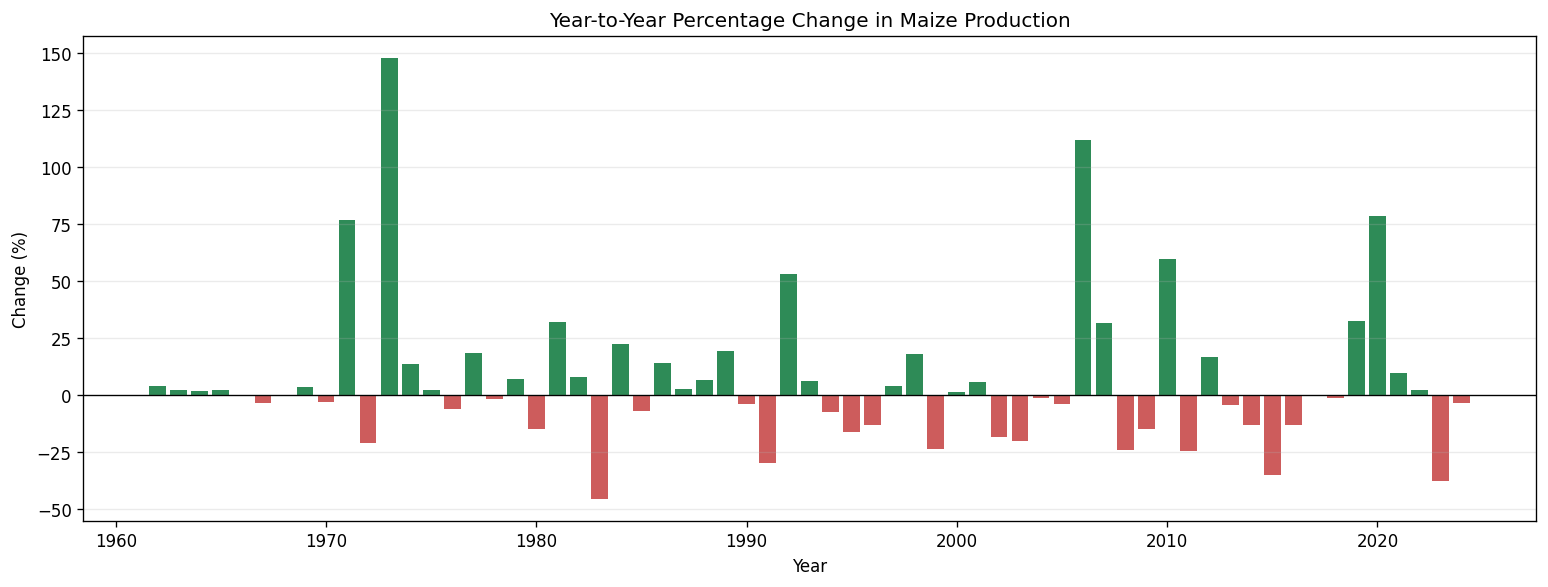

Saved: /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/figures/05_annual_production_change.png


In [13]:
# 7. Annual Production Changes and Descriptive Statistics

change_df = annual_df.sort_values("Year").copy()

change_df["Production_Change"] = change_df["Production"].diff()

change_df["Production_Pct_Change"] = (
    change_df["Production"]
    .pct_change(fill_method=None)
    .mul(100)
)

# Summary statistics
print("PRODUCTION SUMMARY")
display(change_df["Production"].describe().to_frame("Production (tonnes)"))

print("\nYEAR-TO-YEAR CHANGE SUMMARY")
display(
    change_df[
        ["Production_Change", "Production_Pct_Change"]
    ].describe().round(2)
)

# Largest absolute annual changes
largest_changes = (
    change_df.dropna(subset=["Production_Change"])
    .assign(
        Absolute_Change=lambda x: x["Production_Change"].abs()
    )
    .nlargest(10, "Absolute_Change")
    [[
        "Year",
        "Production",
        "Production_Flag",
        "Production_Change",
        "Production_Pct_Change"
    ]]
    .sort_values("Year")
)

print("\n10 LARGEST ABSOLUTE ANNUAL CHANGES")
display(largest_changes.round(2))

# Plot annual percentage change
fig, ax = plt.subplots(figsize=(13, 5))

colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in change_df["Production_Pct_Change"].fillna(0)
]

ax.bar(
    change_df["Year"],
    change_df["Production_Pct_Change"],
    color=colors,
    width=0.8
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Year-to-Year Percentage Change in Maize Production")
ax.set_xlabel("Year")
ax.set_ylabel("Change (%)")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "05_annual_production_change.png",
    bbox_inches="tight"
)
plt.show()

print("Saved:", FIGURES_DIR / "05_annual_production_change.png")

## 8. Temporal Model Evaluation

Forecasting models must be evaluated using chronological validation rather than random train-test splitting. This preserves the time order and reduces the risk of using future information to predict the past.

Previously saved walk-forward evaluation results are reused in this section to compare forecasting methods across one-, two-, and three-year horizons. The final method should be selected according to the forecast horizon, evaluation metric, and intended use.

In [14]:
# 8. Load and Compare Saved Temporal Evaluation Results

WALK_FORWARD_FILE = PROJECT_DIR / "Stage40_WalkForward_Metrics.csv"
METHODS_FILE = PROJECT_DIR / "Stage40_Method_Summary.csv"
PERIOD_FILE = PROJECT_DIR / "Stage41_Period_Metrics.csv"
FLAG_FILE = PROJECT_DIR / "Stage41_Flag_Metrics.csv"

# 1. Overall model comparison
if METHODS_FILE.exists():
    methods_df = pd.read_csv(METHODS_FILE)

    print("OVERALL MODEL COMPARISON")
    display(
        methods_df.sort_values("Mean_MAE_Across_Horizons")
        .round(2)
    )
else:
    print("Method summary file not found:", METHODS_FILE)


# 2. Walk-forward results by forecast horizon
if WALK_FORWARD_FILE.exists():
    walk_forward_df = pd.read_csv(WALK_FORWARD_FILE)

    print("\nWALK-FORWARD METRICS")
    print("Columns:", walk_forward_df.columns.tolist())
    display(walk_forward_df.head(15))
else:
    print("Walk-forward metrics file not found:", WALK_FORWARD_FILE)


# 3. Performance by historical period
if PERIOD_FILE.exists():
    period_df = pd.read_csv(PERIOD_FILE)

    print("\nPERFORMANCE BY HISTORICAL PERIOD")
    print("Columns:", period_df.columns.tolist())
    display(period_df)
else:
    print("Period metrics file not found:", PERIOD_FILE)


# 4. Performance by production quality flag
if FLAG_FILE.exists():
    flag_df = pd.read_csv(FLAG_FILE)

    print("\nPERFORMANCE BY PRODUCTION FLAG")
    print("Columns:", flag_df.columns.tolist())
    display(flag_df)
else:
    print("Flag metrics file not found:", FLAG_FILE)

OVERALL MODEL COMPARISON


,Method,Horizons_Evaluated,Mean_MAE_Across_Horizons,Mean_RMSE_Across_Horizons
0,Ridge_Area_Yield,3,14935.42,18842.50
1,Ridge_Direct,3,15086.92,18777.68
2,Previous_Year,3,15861.05,20637.84
3,Three_Year_Average,3,16436.59,20932.07
4,Ridge_Log_Change,3,18034.83,23265.50



WALK-FORWARD METRICS
Columns: ['Method', 'Horizon', 'Test_Points', 'Unique_Target_Years', 'MAE', 'RMSE', 'Mean_Signed_Error']


,Method,Horizon,Test_Points,Unique_Target_Years,MAE,RMSE,Mean_Signed_Error
0,Previous_Year,1,44,44,11565.000000,15786.264762,-136.363636
1,Three_Year_Average,1,44,44,14399.053030,18100.455523,-421.386364
2,Ridge_Direct,1,44,44,12758.416567,15817.989056,-1266.549886
3,Ridge_Log_Change,1,44,44,12733.311643,17269.775189,2712.919294
4,Ridge_Area_Yield,1,44,44,12577.600707,15769.627256,562.804213
5,Previous_Year,2,43,43,16991.465116,21951.233722,62.906977
6,Three_Year_Average,2,43,43,17078.245478,21552.658695,-493.914729
7,Ridge_Direct,2,43,43,16231.738556,19714.219833,-1785.149186
8,Ridge_Log_Change,2,43,43,18528.673708,24453.130423,5610.542387
9,Ridge_Area_Yield,2,43,43,15861.859886,19690.380612,631.701219



PERFORMANCE BY HISTORICAL PERIOD
Columns: ['Period', 'Horizon', 'Method', 'Test_Points', 'MAE', 'RMSE', 'Mean_Signed_Error']


,Period,Horizon,Method,Test_Points,MAE,RMSE,Mean_Signed_Error
0,2000-2009,1,Previous_Year,10,10856.600000,15261.677634,-901.000000
1,2000-2009,1,Ridge_Area_Yield,10,12975.927401,16892.150908,-347.455874
2,2000-2009,1,Ridge_Direct,10,12230.542619,16597.624963,-1163.893692
3,2000-2009,1,Ridge_Log_Change,10,13535.076343,17610.718559,864.959224
4,2000-2009,1,Three_Year_Average,10,14063.133333,19251.687408,-2306.466667
5,2000-2009,2,Previous_Year,10,17155.500000,24027.239952,-1298.100000
6,2000-2009,2,Ridge_Area_Yield,10,17495.023899,21380.327747,-707.135179
7,2000-2009,2,Ridge_Direct,10,16700.242502,20973.114656,-2010.722419
8,2000-2009,2,Ridge_Log_Change,10,19736.893918,25920.892767,2034.129080
9,2000-2009,2,Three_Year_Average,10,17855.922222,22972.872463,-3371.611111



PERFORMANCE BY PRODUCTION FLAG
Columns: ['Production_Flag', 'Horizon', 'Method', 'Test_Points', 'MAE', 'RMSE', 'Mean_Signed_Error']


,Production_Flag,Horizon,Method,Test_Points,MAE,RMSE,Mean_Signed_Error
0,A,1,Previous_Year,35,10197.657143,13715.138941,34.628571
1,A,1,Ridge_Area_Yield,35,10656.961208,13544.849656,1237.574060
2,A,1,Ridge_Direct,35,10948.728825,13656.355690,-421.076472
3,A,1,Ridge_Log_Change,35,11573.314682,14994.089470,2646.403682
4,A,1,Three_Year_Average,35,11723.447619,14877.049681,466.704762
5,A,2,Previous_Year,35,13606.142857,18079.229242,149.628571
6,A,2,Ridge_Area_Yield,35,13054.415984,16393.897453,2151.004783
7,A,2,Ridge_Direct,35,13502.318389,16325.538575,-359.271302
8,A,2,Ridge_Log_Change,35,14637.980838,20053.786482,5511.863881
9,A,2,Three_Year_Average,35,13713.955556,17398.151522,842.971429


## 9. Forecasts for 2025–2027

This section reviews the previously saved recursive forecasts for 2025–2027. Forecasts are compared across methods, while their training periods and assumptions are documented.

These values are model-based estimates, not confirmed agricultural statistics. Uncertainty is particularly important because recent production records include unofficial figures and some recent area and yield values are estimated or imputed.

SAVED FORECASTS


,Model,Year,Prediction,Training_Records,Training_End_Year
0,Previous_Year,2025,58000.00,NaN,NaN
4,Previous_Year,2026,58000.00,NaN,NaN
8,Previous_Year,2027,58000.00,NaN,NaN
1,Ridge_A_and_X_alpha_10,2025,59306.23,60.0,2024.0
5,Ridge_A_and_X_alpha_10,2026,58367.77,60.0,2024.0
9,Ridge_A_and_X_alpha_10,2027,57366.49,60.0,2024.0
2,Ridge_A_only_alpha_10,2025,59974.43,40.0,2019.0
6,Ridge_A_only_alpha_10,2026,58247.07,40.0,2019.0
10,Ridge_A_only_alpha_10,2027,56672.06,40.0,2019.0
3,Three_Year_Average,2025,71541.00,NaN,NaN



FORECAST COMPARISON TABLE (tonnes)


Model,Previous_Year,Ridge_A_and_X_alpha_10,Ridge_A_only_alpha_10,Three_Year_Average
Year,,,,
2025,58000.0,59306.0,59974.0,71541.0
2026,58000.0,58368.0,58247.0,63180.0
2027,58000.0,57366.0,56672.0,64240.0


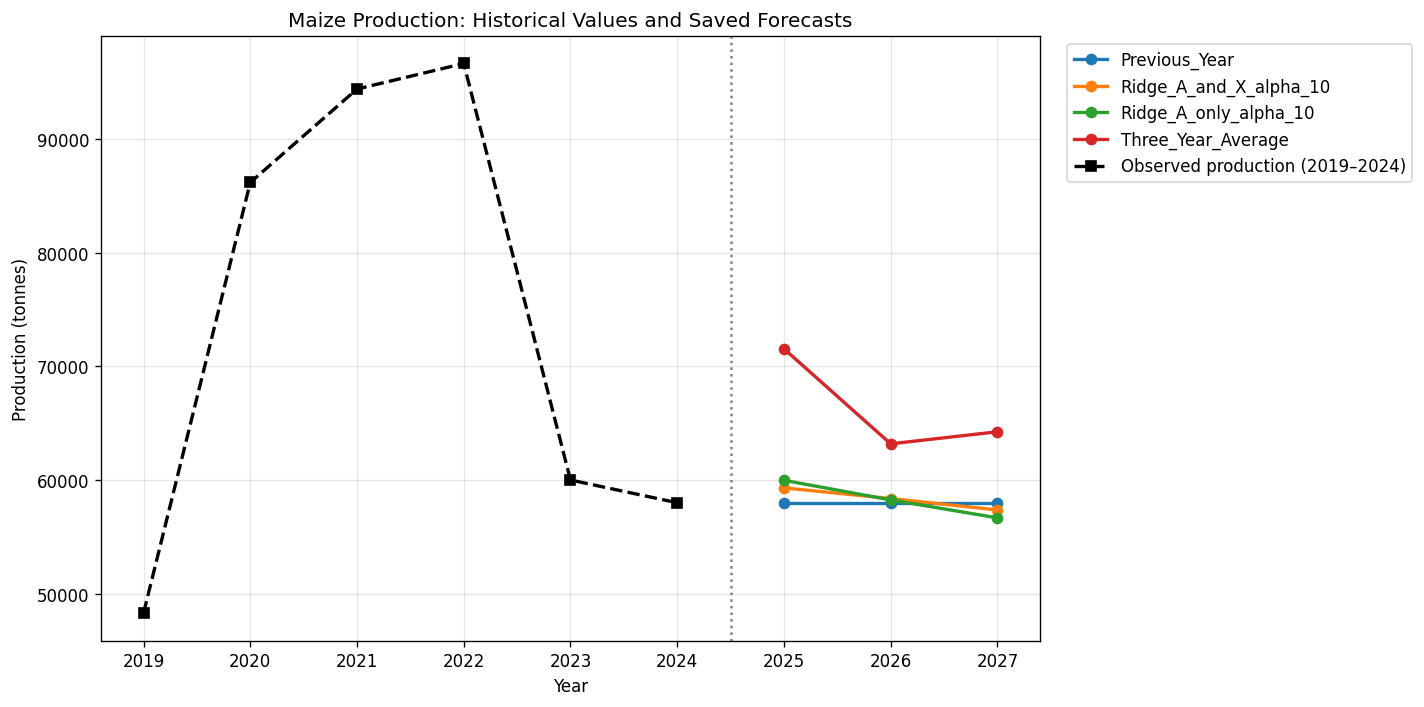

Forecast figure saved to: /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/figures/06_forecasts_2025_2027.png


In [15]:
# 9. Review Saved Forecasts for 2025–2027

FORECAST_FILE = PROJECT_DIR / "Stage27_Recursive_Forecasts_2025_2027.csv"

forecasts_df = pd.read_csv(FORECAST_FILE)

# Validate required columns
required_columns = {"Model", "Year", "Prediction"}
missing_columns = required_columns - set(forecasts_df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

forecasts_df = forecasts_df.sort_values(["Model", "Year"]).copy()

print("SAVED FORECASTS")
display(forecasts_df.round(2))

# Pivot forecasts for easier comparison
forecast_table = forecasts_df.pivot(
    index="Year",
    columns="Model",
    values="Prediction"
)

print("\nFORECAST COMPARISON TABLE (tonnes)")
display(forecast_table.round(0))

# Plot forecast paths
fig, ax = plt.subplots(figsize=(12, 6))

for model_name, model_data in forecasts_df.groupby("Model"):
    model_data = model_data.sort_values("Year")

    ax.plot(
        model_data["Year"],
        model_data["Prediction"],
        marker="o",
        linewidth=2,
        label=model_name
    )

# Reference: observed production through 2024
historical_tail = annual_df.loc[
    annual_df["Year"].between(2019, 2024)
].sort_values("Year")

ax.plot(
    historical_tail["Year"],
    historical_tail["Production"],
    color="black",
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Observed production (2019–2024)"
)

ax.axvline(2024.5, color="gray", linestyle=":", linewidth=1.5)
ax.set_title("Maize Production: Historical Values and Saved Forecasts")
ax.set_xlabel("Year")
ax.set_ylabel("Production (tonnes)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

forecast_plot = FIGURES_DIR / "06_forecasts_2025_2027.png"
fig.savefig(forecast_plot, bbox_inches="tight")
plt.show()

print("Forecast figure saved to:", forecast_plot)

## 10. Conclusions, Limitations, and Recommendations

### Main Findings
- Historical maize production in Yemen varies substantially across years.
- Temporal evaluation shows that model performance depends on the forecast horizon and evaluation period.
- Ridge models achieved competitive average errors, while simple baselines remain important reference points.
- Forecasts from the three-year average differ noticeably from Ridge-based forecasts.

### Data Limitations
- Production observations for 2020–2024 carry the `X` flag and are marked as unofficial figures.
- Harvested area for 2023–2024 is imputed, and yield for those years is estimated.
- Rainfall data are available only for 1981–2024.
- The historical dataset is relatively small and contains substantial year-to-year variation.

### Modeling Limitations
- Historical walk-forward performance does not guarantee future accuracy.
- Forecasts using harvested area and yield require future values of those variables to be available or forecast independently.
- Forecasts for 2026–2027 are recursive or multi-step estimates and may accumulate errors.
- Rainfall associations should not be interpreted as evidence of causation.

### Recommendations
- Treat forecasts as planning estimates rather than confirmed production figures.
- Update the dataset when reliable new agricultural statistics become available.
- Continue reporting baseline performance alongside machine-learning models.
- Document the data-quality flags and forecast assumptions in any presentation or report.

In [16]:
# 10. Save Final Project Summary Tables

# Save the forecast comparison table
forecast_table_path = RESULTS_DIR / "Final_Forecast_Comparison_2025_2027.csv"
forecast_table.to_csv(forecast_table_path, index=True)

# Save the overall model comparison
model_summary_path = RESULTS_DIR / "Final_Model_Comparison.csv"

if METHODS_FILE.exists():
    methods_df.sort_values(
        "Mean_MAE_Across_Horizons"
    ).to_csv(model_summary_path, index=False)

# Save a concise data-quality summary
quality_report = pd.DataFrame({
    "Check": [
        "First year",
        "Last year",
        "Number of annual records",
        "Missing years",
        "Duplicate years",
        "Missing rainfall values",
        "Production records flagged X",
        "Production records flagged A",
        "Production records flagged E"
    ],
    "Result": [
        int(annual_df["Year"].min()),
        int(annual_df["Year"].max()),
        len(annual_df),
        0,
        int(annual_df["Year"].duplicated().sum()),
        int(annual_df["Rainfall_mm"].isna().sum()),
        int((annual_df["Production_Flag"] == "X").sum()),
        int((annual_df["Production_Flag"] == "A").sum()),
        int((annual_df["Production_Flag"] == "E").sum())
    ]
})

quality_report_path = RESULTS_DIR / "Final_Data_Quality_Summary.csv"
quality_report.to_csv(quality_report_path, index=False)

print("Final summary files saved:")
print(f"- {forecast_table_path}")
print(f"- {model_summary_path}")
print(f"- {quality_report_path}")

Final summary files saved:
- /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/Final_Forecast_Comparison_2025_2027.csv
- /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/Final_Model_Comparison.csv
- /content/drive/MyDrive/Yemen_Maize_Prediction/05_Results/Final_Data_Quality_Summary.csv


In [17]:
# 11. Final Output Audit

print("SAVED FIGURES")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

print("\nSAVED SUMMARY TABLES")
for filename in [
    "Final_Forecast_Comparison_2025_2027.csv",
    "Final_Model_Comparison.csv",
    "Final_Data_Quality_Summary.csv"
]:
    path = RESULTS_DIR / filename
    print(f"- {filename}: {'OK' if path.exists() else 'MISSING'}")

print("\nPROJECT DATASETS")
print("Annual dataset:", annual_df.shape)
print("Temporal dataset:", temporal_df.shape)
print("Rainfall dataset:", rainfall_df.shape)

SAVED FIGURES
- 01_maize_production_history.png (78,531 bytes)
- 02_area_and_yield.png (105,272 bytes)
- 03_rainfall_and_production.png (132,691 bytes)
- 04_production_flag_counts.png (23,425 bytes)
- 05_annual_production_change.png (30,537 bytes)
- 06_forecasts_2025_2027.png (81,359 bytes)

SAVED SUMMARY TABLES
- Final_Forecast_Comparison_2025_2027.csv: OK
- Final_Model_Comparison.csv: OK
- Final_Data_Quality_Summary.csv: OK

PROJECT DATASETS
Annual dataset: (64, 15)
Temporal dataset: (64, 21)
Rainfall dataset: (44, 15)
